In [6]:
from pathlib import Path
import polars as pl

out_dir = r'Z:\ResearchHome\ClusterHome\yfu\projects\dia_dev\benchmark\nc_tims\jumpdiaq\default_20251023\intermediate\prec_quant'

quantity_df = pl.read_parquet(Path(out_dir) / "Precursor.Id_MS2.XIC.Quant.Raw_mapping.parquet")
quality_df = pl.read_parquet(Path(out_dir) / "Precursor.Id_MS2.XIC.Corr.Raw_mapping.parquet")

print(quantity_df.columns)
print(quality_df.columns)

['target_id', 'samples', 'source_id', 'source_quantity']
['target_id', 'samples', 'source_id', 'source_quality']


In [7]:
# Pivot input tables
quantity_pivoted = quantity_df.pivot(
    values="source_quantity",
    index=["target_id", "source_id"],
    on="samples",
    aggregate_function="first"
)
quality_pivoted = quality_df.pivot(
    values="source_quality",
    index=["target_id", "source_id"],
    on="samples",
    aggregate_function="first"
)

sample_cols = [col for col in quantity_pivoted.columns if col not in {"target_id", "source_id"}]

# Group by precursor for fast lookup
quantity_groups = quantity_pivoted.partition_by("target_id", as_dict=True)
quality_groups = quality_pivoted.partition_by("target_id", as_dict=True)
print('done')

done


In [10]:
prec_id = 'SVEDVYK2'
quantity_df_sub = quantity_groups.get((prec_id,))
quality_df_sub = quality_groups.get((prec_id,))

quantity_mat = quantity_df_sub.select(sample_cols).to_numpy()
quality_mat = quality_df_sub.select(sample_cols).to_numpy()

print(quantity_mat)
print(quality_mat)

[[ 5454.  3883.  5215.  3146.  3631.  1827.  3480.  4276.  3402.  2705.
  10491.  9870.  8665.  9993. 10804. 11781. 13973. 13282. 11676.  9959.]
 [  627.   697.   825.   475.   578.   522.   389.   449.   597.   289.
   1470.  1569.  1549.  2222.  1316.  2569.  1705.  1945.  1648.  1757.]
 [  383.   296.   898.   397.   225.   278.   109.   533.   306.   512.
   1824.  1022.  1164.   951.  1295.   895.   954.  1095.  1233.  1106.]
 [  348.   311.   392.   542.   372.   198.   185.   234.   307.   135.
    335.   445.   549.   456.   497.   368.   466.   283.   240.   374.]
 [   98.   242.     0.     0.     0.     0.   152.     0.     0.    69.
      0.     0.    64.   308.   142.    97.   189.     0.    88.   155.]
 [    0.     0.     0.     0.     0.     0.     0.     0.     0.    30.
      0.   141.     0.    73.     0.    74.     0.     0.    93.   101.]]
[[ 0.8775674   0.91554362  0.94891246  0.52439159  0.82504246  0.78622682
   0.87080944  0.86330898  0.70998932  0.75607449  0.91

In [18]:
from jumpdiaq.summarization import median_summ

quantity_mat_fill = quantity_mat.copy()
quantity_direct = median_summ(quantity_mat_fill, topN_rep=3)

In [19]:
import numpy as np

fill_missing_xic = True
xic_quality_cutoff = 0.0

if fill_missing_xic:
    if xic_quality_cutoff <= 0.0:
        missing_mask = (quality_mat < xic_quality_cutoff) | (quality_mat == 0.0)
    else:
        missing_mask = quality_mat < xic_quality_cutoff
    missing_mask = missing_mask | (quantity_mat == 0.0)
    quantity_mat_fill[missing_mask] = np.nan
    # remove rows that contain all NaNs
    quantity_mat_fill = quantity_mat_fill[~np.all(np.isnan(quantity_mat_fill), axis=1)]

print(quantity_mat_fill)

[[ 5454.  3883.  5215.  3146.  3631.  1827.  3480.  4276.  3402.  2705.
  10491.  9870.  8665.  9993. 10804. 11781. 13973. 13282. 11676.  9959.]
 [  627.   697.   825.   475.   578.   522.    nan   449.   597.   289.
   1470.  1569.  1549.  2222.  1316.  2569.  1705.  1945.  1648.  1757.]
 [  383.   296.   898.    nan   225.   278.   109.   533.   306.   512.
   1824.  1022.  1164.   951.  1295.   895.   954.  1095.  1233.  1106.]
 [  348.   311.    nan   542.   372.   198.   185.   234.    nan    nan
    335.   445.   549.   456.   497.   368.   466.   283.   240.   374.]
 [   98.   242.    nan    nan    nan    nan   152.    nan    nan    nan
     nan    nan    64.   308.   142.    nan   189.    nan    88.   155.]
 [   nan    nan    nan    nan    nan    nan    nan    nan    nan    30.
     nan    nan    nan    nan    nan    74.    nan    nan    nan   101.]]


In [20]:
from jumpdiaq.utils import missing_value_imputation

fill_method = 'global_min'
sample_meta = pd.read_csv(r"Z:\ResearchHome\ClusterHome\yfu\projects\dia_dev\benchmark\nc_tims\sample_meta.csv")

# fill missing value
quantity_mat_fill_global = missing_value_imputation(quantity_mat_fill, 
                                             sample_cols, 
                                             sample_meta,
                                             fill_method)
print(quantity_mat_fill_global)
quantity_global = median_summ(quantity_mat_fill_global, topN_rep=3)

[[ 5454.  3883.  5215.  3146.  3631.  1827.  3480.  4276.  3402.  2705.
  10491.  9870.  8665.  9993. 10804. 11781. 13973. 13282. 11676.  9959.]
 [  627.   697.   825.   475.   578.   522.    30.   449.   597.   289.
   1470.  1569.  1549.  2222.  1316.  2569.  1705.  1945.  1648.  1757.]
 [  383.   296.   898.    30.   225.   278.   109.   533.   306.   512.
   1824.  1022.  1164.   951.  1295.   895.   954.  1095.  1233.  1106.]
 [  348.   311.    30.   542.   372.   198.   185.   234.    30.    30.
    335.   445.   549.   456.   497.   368.   466.   283.   240.   374.]
 [   98.   242.    30.    30.    30.    30.   152.    30.    30.    30.
     30.    30.    64.   308.   142.    30.   189.    30.    88.   155.]
 [   30.    30.    30.    30.    30.    30.    30.    30.    30.    30.
     30.    30.    30.    30.    30.    74.    30.    30.    30.   101.]]


In [21]:
fill_method = 'local_min'

# fill missing value
quantity_mat_fill_local = missing_value_imputation(quantity_mat_fill, 
                                             sample_cols, 
                                             sample_meta,
                                             fill_method)
print(quantity_mat_fill_local)
quantity_local = median_summ(quantity_mat_fill_local, topN_rep=3)

[[ 5454.  3883.  5215.  3146.  3631.  1827.  3480.  4276.  3402.  2705.
  10491.  9870.  8665.  9993. 10804. 11781. 13973. 13282. 11676.  9959.]
 [  627.   697.   825.   475.   578.   522.    30.   449.   597.   289.
   1470.  1569.  1549.  2222.  1316.  2569.  1705.  1945.  1648.  1757.]
 [  383.   296.   898.    98.   225.   278.   109.   533.   306.   512.
   1824.  1022.  1164.   951.  1295.   895.   954.  1095.  1233.  1106.]
 [  348.   311.    98.   542.   372.   198.   185.   234.    30.    30.
    335.   445.   549.   456.   497.   368.   466.   283.   240.   374.]
 [   98.   242.    98.    98.    98.    30.   152.    30.    30.    30.
     64.    64.    64.   308.   142.    74.   189.    74.    88.   155.]
 [   98.    98.    98.    98.    98.    30.    30.    30.    30.    30.
     64.    64.    64.    64.    64.    74.    74.    74.    74.   101.]]


Text(0, 0.5, 'Global')

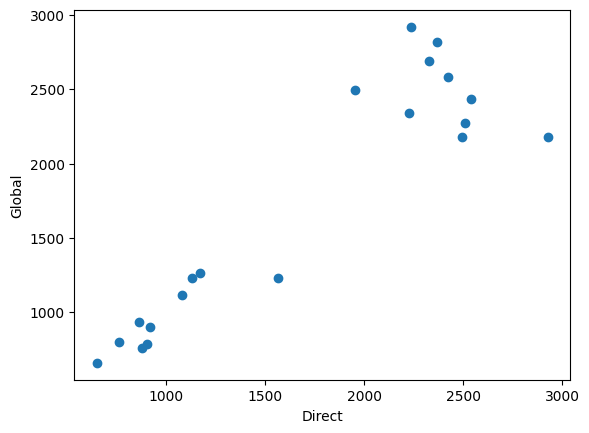

In [24]:
import matplotlib.pyplot as plt

plt.scatter(quantity_direct, quantity_global)
plt.xlabel("Direct")
plt.ylabel("Global")

Text(0, 0.5, 'Local')

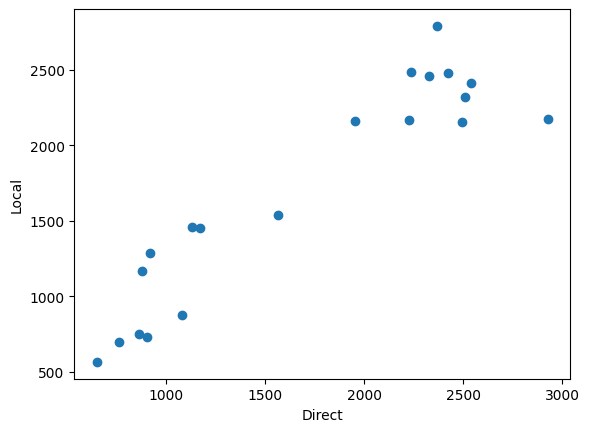

In [25]:
plt.scatter(quantity_direct, quantity_local)
plt.xlabel("Direct")
plt.ylabel("Local")

Text(0, 0.5, 'Local')

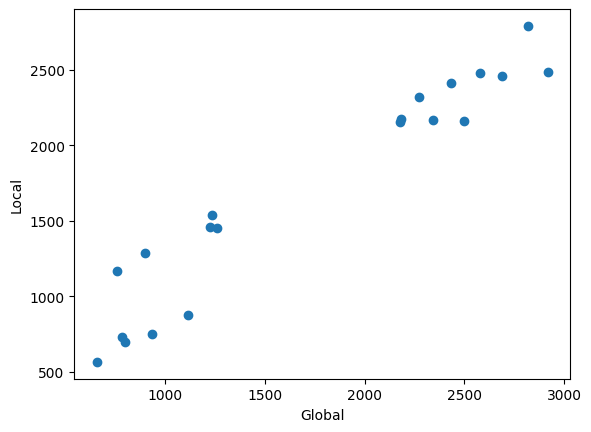

In [26]:
plt.scatter(quantity_global, quantity_local)
plt.xlabel("Global")
plt.ylabel("Local")